# 1-02 NXT 점유율 추이 — 일별·종목별 기간 합계와 개장 이후 월별 흐름

**질문 예시:** "최근 석 달 넥스트레이드 비중이 늘었어?", "이번 분기 NXT에서 많이 거래된 종목은?", "NXT 개장 이후 점유율이 어떻게 변했어?"

원본은 `krxnewsscrap`의 `krxvsnxt_cumul.ipynb`입니다(개장일부터 입력일까지 매일 NXT·KRX를 받아 날짜별·종목별로 합산).
여기서는 같은 계산을 두 단계로 나눴습니다. 최근 구간은 **매일**, 개장 이후 전체는 **월말 거래일 하루씩** 받아 호출 수를 줄입니다.

| 항목 | 출처 |
|---|---|
| 매매거래일 목록 | `krx_data_api.daily_snapshots.trading_days` (삼성전자 [12003] 시세추이의 일자) |
| NXT 거래량·거래대금 | `nxt_data_api.fetch_range` — `regular_market` + `closing_price` + `block_trade` |
| KRX 거래량·거래대금 | `krx_data_api` `all_stock_price` ([12001] 전종목시세, 하루 1회 호출) |

비중의 정의와 모집단 구분(NXT 거래종목 / 시장 전체)은 [1-01](01_daily_share.ipynb)과 같습니다.
**NXT점유율 = NXT ÷ (NXT + KRX)**, NXT/KRX는 원본의 "비중"입니다.

[![Colab에서 열기](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/beaten-by-the-market/nxt-data-api/blob/main/scenarios/1_nxt_vs_krx/02_share_trend.ipynb)

## 0. 준비
넥스트레이드(NXT) 데이터는 로그인이 필요 없지만, KRX 정보데이터시스템은 2026-09부터 로그인해야 합니다. Colab 왼쪽 🔑(Secrets)에 `KRX_ID`, `KRX_PW`를 등록하고 이 노트북의 액세스를 켠 뒤 아래 두 셀을 실행하세요. 두 번째 셀은 모든 시나리오에 공통인 헬퍼입니다(접어 두어도 됩니다).

In [1]:
# Colab에서만: 패키지 설치 (로컬에서는 건너뜀)
import sys
if "google.colab" in sys.modules:
    !pip -q install koreanize-matplotlib \
        git+https://github.com/beaten-by-the-market/nxt-data-api.git \
        git+https://github.com/beaten-by-the-market/krx-data-api.git

In [2]:
# ── NXT·KRX 헬퍼 (모든 시나리오 노트북 공통) ─────────────────────────────
# NXT(넥스트레이드): nxt_data_api — 로그인 불필요.
# KRX(정보데이터시스템): krx_data_api — 2026-09부터 로그인 필요.
#   Colab: 왼쪽 🔑(Secrets)에 KRX_ID, KRX_PW 를 넣고 "노트북 액세스"를 켜세요. 값은 출력하지 않습니다.
#   로컬: 환경변수 → 작업 폴더 .env → (편집 가능 설치라면) krx-data-api 레포의 .env 순서로 찾습니다.
import os, sys, time
from datetime import date, datetime, timedelta

import numpy as np
import pandas as pd

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import userdata
    for _k in ("KRX_ID", "KRX_PW"):
        try:
            _v = userdata.get(_k)
            if _v:
                os.environ[_k] = _v
        except Exception as _e:  # SecretNotFoundError / NotebookAccessError
            print(f"Colab Secrets에서 {_k}를 읽지 못했습니다 ({type(_e).__name__}). 🔑에 등록하고 액세스를 켜세요.")

from nxt_data_api import fetch as nxt_fetch, fetch_range as nxt_fetch_range
from krx_data_api import fetch as krx_fetch
from krx_data_api.daily_snapshots import trading_days  # KRX 매매거래일 목록 (삼성전자 시세추이의 일자)

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 40)

MARKETS = ["KOSPI", "KOSDAQ"]  # NXT는 코넥스 종목을 거래하지 않습니다


def _num(s):
    """'1,234' / '-' / '' 같은 문자열 → 숫자 (없으면 NaN)."""
    return pd.to_numeric(s.astype(str).str.replace(",", "", regex=False).str.strip()
                         .replace({"-": None, "": None, "None": None, "nan": None}), errors="coerce")


def _as_list(dates):
    return [dates] if isinstance(dates, (str, date, datetime)) else list(dates)


def nxt_volume(dates, pause=0.1):
    """NXT 종목별·일별 거래량/거래대금. dates: 'YYYYMMDD' 하나 또는 목록.

    NXT 하루 총거래량 = 정규시장(regular_market) + 종가매매(closing_price) + 대량·바스켓(block_trade).
    세 화면은 서로 겹치지 않습니다(block_trade 의 isuAccTdQty 와 원 단위로 일치, 2026-02-06 삼성전자).
    거래대금은 정규시장 + 종가매매만 있습니다(대량·바스켓 화면에 거래대금이 없음).
    """
    days = [pd.Timestamp(d).strftime("%Y%m%d") for d in _as_list(dates)]
    kw = dict(dates=days, pause=pause)
    reg = nxt_fetch_range("regular_market", days[0], days[-1], **kw)
    if reg.empty:
        return pd.DataFrame()
    clo = nxt_fetch_range("closing_price", days[0], days[-1], **kw)
    blk = nxt_fetch_range("block_trade", days[0], days[-1], **kw)

    def key(df):
        return df.assign(일자=df["aggDd"].astype(str), 코드=df["isuSrdCd"].str[1:])  # 'A005930' → '005930'

    out = key(reg).rename(columns={"isuAbwdNm": "종목명", "mktNm": "시장", "accTdQty": "NXT정규량",
                                   "accTrval": "NXT정규대금", "cptrTrdPmsnCdNm": "NXT거래가능",
                                   "trdIpsbRsn": "NXT거래불가사유"})
    out = out[["일자", "코드", "종목명", "시장", "NXT정규량", "NXT정규대금", "NXT거래가능", "NXT거래불가사유"]]
    if not clo.empty:
        c = key(clo).rename(columns={"accTdQty": "NXT종가량", "accTrval": "NXT종가대금"})
        extra = set(zip(c["일자"], c["코드"])) - set(zip(out["일자"], out["코드"]))
        if extra:
            print(f"주의: 종가매매에만 있고 정규시장 목록에 없는 종목 {len(extra)}건 (합계에서 빠짐)")
        out = out.merge(c[["일자", "코드", "NXT종가량", "NXT종가대금"]], on=["일자", "코드"], how="left")
    else:
        out["NXT종가량"], out["NXT종가대금"] = 0, 0
    if not blk.empty:
        b = key(blk).assign(NXT대량량=lambda x: _num(x["bltdAccTdQty"]))
        b = b.groupby(["일자", "코드"], as_index=False)["NXT대량량"].sum()
        out = out.merge(b, on=["일자", "코드"], how="left")
    else:
        out["NXT대량량"] = 0
    for c in ("NXT정규량", "NXT정규대금", "NXT종가량", "NXT종가대금", "NXT대량량"):
        out[c] = pd.to_numeric(out[c], errors="coerce").fillna(0)
    out["NXT거래량"] = out["NXT정규량"] + out["NXT종가량"] + out["NXT대량량"]
    out["NXT거래대금"] = out["NXT정규대금"] + out["NXT종가대금"]
    # 정규시장 스냅샷 적재 시각 (일자별 최댓값). 20시 이후면 애프터마켓까지 들어간 값입니다
    out.attrs["loaded_at"] = reg.groupby("aggDd")["registDt"].max().dt.strftime("%Y-%m-%d %H:%M").to_dict()
    out.attrs["empty_dates"] = reg.attrs.get("empty_dates", [])
    return out


def krx_prices(day):
    """KRX [12001] 전종목시세 하루치 (all_stock_price, JSON). 영문 코드 컬럼을 명시적으로 한글로 바꿉니다.
    거래량·거래대금은 KRX에서 체결된 것만입니다(NXT 미포함)."""
    day = pd.Timestamp(day).strftime("%Y%m%d")
    raw = krx_fetch("all_stock_price", trdDd=day)
    df = pd.DataFrame({
        "일자": day,
        "코드": raw["ISU_SRT_CD"].astype(str).str.strip(),      # 6자리 단축코드
        "KRX종목명": raw["ISU_ABBRV"].astype(str).str.strip(),
        "KRX시장": raw["MKT_NM"].astype(str).str.strip().replace({"KOSDAQ GLOBAL": "KOSDAQ"}),
        "소속부": raw["SECT_TP_NM"].astype(str).str.strip() if "SECT_TP_NM" in raw else "",
        "KRX종가": _num(raw["TDD_CLSPRC"]),
        "KRX거래량": _num(raw["ACC_TRDVOL"]),
        "KRX거래대금": _num(raw["ACC_TRDVAL"]),
        "시가총액": _num(raw["MKTCAP"]),
    })
    if df["KRX거래량"].notna().sum() == 0:  # 휴장일은 값이 전부 '-' 로 옵니다
        raise ValueError(f"{day}: KRX 거래 데이터가 없습니다(휴장일이거나 아직 집계 전).")
    return df


def krx_range(dates, pause=0.3):
    """여러 거래일의 KRX 전종목시세를 이어 붙입니다 (하루 1회 호출)."""
    days = _as_list(dates)
    parts = []
    for i, d in enumerate(days):
        parts.append(krx_prices(d))
        if pause and i < len(days) - 1:
            time.sleep(pause)
    return pd.concat(parts, ignore_index=True)


def compare(nxt, krx):
    """NXT·KRX를 (일자, 6자리 코드)로 outer join 하고 비중을 계산합니다.

    거래소: 'NXT·KRX' (둘 다 있음) / 'KRX만' (NXT 거래 대상이 아닌 종목) / 'NXT만' (KRX 목록에 없음 — 보통 0건)
    NXT점유율(%)  = NXT / (NXT + KRX) × 100   ← 두 거래소 합계 중 NXT 몫 (0~100)
    NXT/KRX(%)   = NXT / KRX × 100           ← 원본 앱의 '비중'. KRX보다 많으면 100을 넘습니다
    """
    df = krx.merge(nxt, on=["일자", "코드"], how="outer", indicator=True)
    df["거래소"] = df["_merge"].map({"both": "NXT·KRX", "left_only": "KRX만", "right_only": "NXT만"})
    df["종목명"] = df["종목명"].fillna(df["KRX종목명"]) if "종목명" in df else df["KRX종목명"]
    df["시장"] = df["KRX시장"].fillna(df.get("시장"))
    df["NXT종목"] = df["거래소"] != "KRX만"
    for c in ("NXT거래량", "NXT거래대금", "KRX거래량", "KRX거래대금"):
        df[c] = df[c].fillna(0)
    df["합계거래량"] = df["NXT거래량"] + df["KRX거래량"]
    df["합계거래대금"] = df["NXT거래대금"] + df["KRX거래대금"]
    df["NXT점유율(%)"] = (df["NXT거래량"] / df["합계거래량"].replace(0, np.nan) * 100).round(2)
    df["NXT대금점유율(%)"] = (df["NXT거래대금"] / df["합계거래대금"].replace(0, np.nan) * 100).round(2)
    df["NXT/KRX(%)"] = (df["NXT거래량"] / df["KRX거래량"].replace(0, np.nan) * 100).round(2)
    return df.drop(columns=["_merge", "KRX종목명", "KRX시장"]).reset_index(drop=True)


def share_summary(df, by=("시장",)):
    """그룹별 합계와 비중. 두 모집단을 나란히 보여 줍니다.
    - 'NXT 거래종목': NXT에서 거래된 종목만 (NXT 종목 vs 같은 종목의 KRX 거래)
    - '시장 전체'   : KOSPI·KOSDAQ 전 종목 (NXT 미거래 종목의 KRX 거래까지 분모에 포함)"""
    by = list(by)
    d = df[df["시장"].isin(MARKETS)]
    rows = []
    for universe, sub in (("NXT 거래종목", d[d["NXT종목"]]), ("시장 전체", d)):
        groups = list(sub.groupby(by))
        # 마지막 기준(보통 '시장')을 합친 '합계' 행도 붙입니다
        if len(by) == 1:
            groups.append((("합계",), sub))
        else:
            groups += [((*(k if isinstance(k, tuple) else (k,)), "합계"), g) for k, g in sub.groupby(by[:-1])]
        for keys, g in groups:
            keys = keys if isinstance(keys, tuple) else (keys,)
            n, k, nv, kv = g["NXT거래량"].sum(), g["KRX거래량"].sum(), g["NXT거래대금"].sum(), g["KRX거래대금"].sum()
            rows.append({"모집단": universe, **dict(zip(by, keys)), "종목수": int(len(g)),
                         "NXT거래량": n, "KRX거래량": k,
                         "NXT점유율(%)": round(n / (n + k) * 100, 2) if n + k else np.nan,
                         "NXT/KRX(%)": round(n / k * 100, 2) if k else np.nan,
                         "NXT거래대금": nv, "KRX거래대금": kv,
                         "NXT대금점유율(%)": round(nv / (nv + kv) * 100, 2) if nv + kv else np.nan})
    return pd.DataFrame(rows)


def krw(v, digits=1):
    """원 → '138.0조' / '5,027억'."""
    if v is None or pd.isna(v):
        return "-"
    a = abs(v)
    if a >= 1e12:
        return f"{v / 1e12:.{digits}f}조"
    if a >= 1e8:
        return f"{v / 1e8:,.0f}억"
    if a >= 1e4:
        return f"{v / 1e4:,.0f}만"
    return f"{v:,.0f}"


def shares(v):
    """주 → '1.2억주' / '3,456만주'."""
    if v is None or pd.isna(v):
        return "-"
    return f"{v / 1e8:.2f}억주" if abs(v) >= 1e8 else f"{v / 1e4:,.0f}만주"


# 차트 색 (시장은 고정 순서: KOSPI 1번, KOSDAQ 2번 / 거래소는 NXT 강조색, KRX 중립 회색)
MKT_COLOR = {"KOSPI": "#2a78d6", "KOSDAQ": "#eb6834"}
NXT_COLOR, KRX_COLOR = "#6250d6", "#c3c2b7"

# 한글 차트 폰트
import matplotlib.pyplot as plt
try:
    import koreanize_matplotlib  # noqa: F401  (Colab: 위 셀에서 설치)
except ImportError:
    if sys.platform.startswith("win"):
        plt.rcParams["font.family"] = "Malgun Gothic"
    elif sys.platform == "darwin":
        plt.rcParams["font.family"] = "AppleGothic"
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

print("NXT·KRX 준비 완료", "(Colab)" if IN_COLAB else "(로컬)",
      "| KRX 계정:", "설정됨" if os.environ.get("KRX_ID") and os.environ.get("KRX_PW") else "없음 — KRX 호출이 거절됩니다")

NXT·KRX 준비 완료 (로컬) | KRX 계정: 설정됨


In [3]:
END = "20261124"          # 마지막 매매거래일
DAILY_START = "20260901"  # 매일 받는 구간의 시작
LAUNCH = "20250304"       # NXT 개장일 (시범 10종목)
MIN_VALUE = 1000e8        # 종목 순위에 넣을 최소 기간 합계 거래대금 (원)
TOP_N = 20

## 1. 매매거래일
NXT는 휴장일에 0건, KRX `all_stock_price`는 휴장일에 값이 전부 `-`로 옵니다. 달력일을 돌지 않고 KRX 매매거래일 목록을 먼저 받습니다.

In [4]:
cal = trading_days(LAUNCH, END)
days = [d for d in cal if d >= DAILY_START]
months = pd.Series(cal, index=pd.to_datetime(cal)).groupby(lambda t: t.strftime("%Y-%m")).last().tolist()
print(f"개장 이후 매매거래일 {len(cal)}일 ({cal[0]} ~ {cal[-1]})")
print(f"일별 구간 {len(days)}일 ({days[0]} ~ {days[-1]}), 월말 표본 {len(months)}일")

개장 이후 매매거래일 423일 (20250304 ~ 20261124)
일별 구간 57일 (20260901 ~ 20261124), 월말 표본 21일


## 2. 일별 추이 (최근 구간)
하루에 NXT 3회 + KRX 1회를 호출합니다. 60거래일이면 2~4분쯤 걸립니다.

In [5]:
t0 = time.time()
nxt = nxt_volume(days)
krx = krx_range(days)
df = compare(nxt, krx)
missing = sorted(set(days) - set(nxt["일자"]))
print(f"{time.time() - t0:.0f}초, {len(df):,}행. NXT 데이터가 없던 KRX 거래일: {missing or '없음'}")

daily = share_summary(df, by=("일자", "시장"))
daily["일자"] = pd.to_datetime(daily["일자"])

def pick(universe, market, col):
    return daily[(daily["모집단"] == universe) & (daily["시장"] == market)].set_index("일자")[col]

tbl = pd.DataFrame({
    "NXT 종목수": pick("NXT 거래종목", "합계", "종목수"),
    "점유율·NXT종목·거래량": pick("NXT 거래종목", "합계", "NXT점유율(%)"),
    "점유율·NXT종목·대금": pick("NXT 거래종목", "합계", "NXT대금점유율(%)"),
    "점유율·시장전체·대금": pick("시장 전체", "합계", "NXT대금점유율(%)"),
    "NXT 거래대금": pick("시장 전체", "합계", "NXT거래대금").map(krw),
    "KRX 거래대금": pick("시장 전체", "합계", "KRX거래대금").map(krw),
})
tbl.index = tbl.index.strftime("%Y-%m-%d")
print("(점유율 단위 %) 처음 5일과 마지막 5일")
pd.concat([tbl.head(5), tbl.tail(5)])

72초, 163,735행. NXT 데이터가 없던 KRX 거래일: 없음


(점유율 단위 %) 처음 5일과 마지막 5일


,NXT 종목수,점유율·NXT종목·거래량,점유율·NXT종목·대금,점유율·시장전체·대금,NXT 거래대금,KRX 거래대금
일자,,,,,,
2026-09-01,606,46.12,37.86,32.34,11.4조,23.9조
2026-09-02,606,44.50,37.52,31.44,11.1조,24.2조
2026-09-03,606,32.59,33.31,28.35,10.7조,27.1조
2026-09-04,606,43.44,36.59,29.68,10.3조,24.4조
2026-09-07,606,46.80,42.33,35.76,15.6조,28.1조
2026-11-18,603,37.93,35.58,28.60,8.7조,21.8조
2026-11-19,603,29.54,28.42,23.00,5.4조,18.2조
2026-11-20,603,38.98,35.40,29.37,8.1조,19.5조
2026-11-23,603,37.85,36.46,30.55,9.1조,20.7조


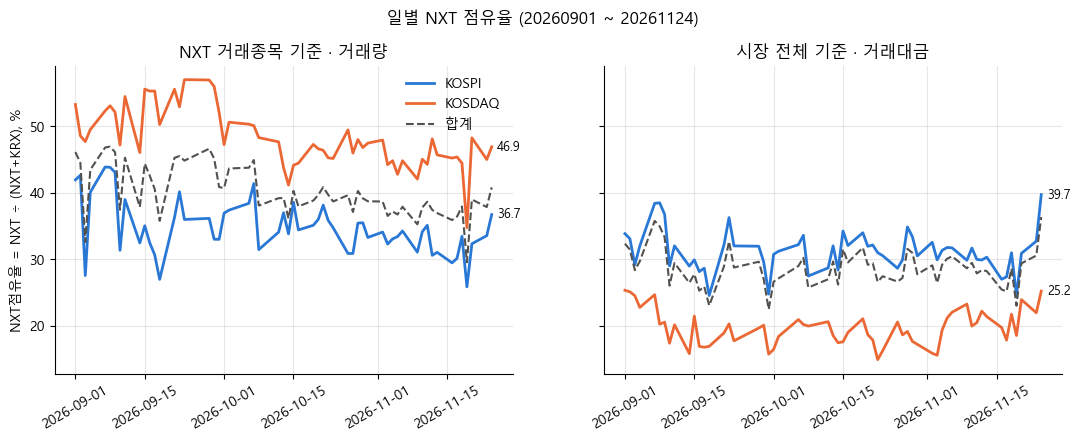

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
panels = [("NXT 거래종목", "NXT점유율(%)", "NXT 거래종목 기준 · 거래량"),
          ("시장 전체", "NXT대금점유율(%)", "시장 전체 기준 · 거래대금")]
for ax, (uni, col, title) in zip(axes, panels):
    for m in MARKETS:
        s = pick(uni, m, col)
        ax.plot(s.index, s.values, color=MKT_COLOR[m], lw=2, label=m)
        ax.annotate(f"{s.iloc[-1]:.1f}", (s.index[-1], s.iloc[-1]), xytext=(4, 0), textcoords="offset points",
                    va="center", fontsize=9)
    s = pick(uni, "합계", col)
    ax.plot(s.index, s.values, color="#52514e", lw=1.5, ls="--", label="합계")
    ax.set_title(title); ax.grid(alpha=.3); ax.tick_params(axis="x", rotation=30)
axes[0].set_ylabel("NXT점유율 = NXT ÷ (NXT+KRX), %")
axes[0].legend(frameon=False)
fig.suptitle(f"일별 NXT 점유율 ({days[0]} ~ {days[-1]})", y=1.02)
plt.show()

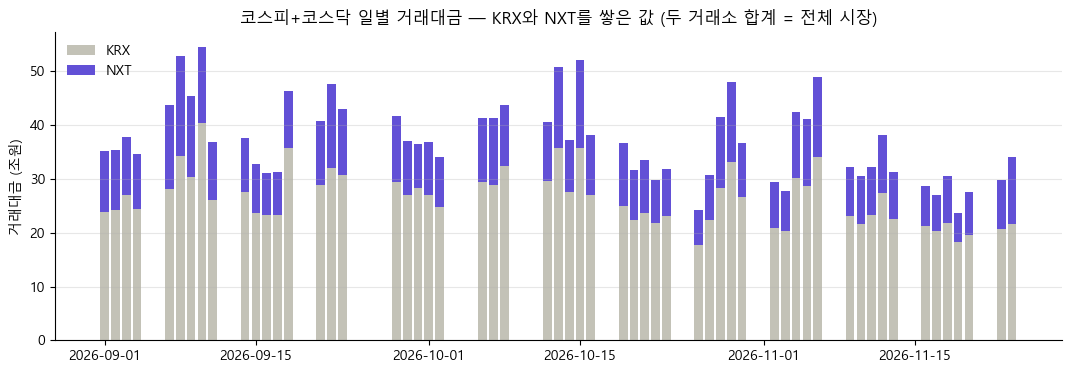

In [7]:
s_n = pick("시장 전체", "합계", "NXT거래대금") / 1e12
s_k = pick("시장 전체", "합계", "KRX거래대금") / 1e12
fig, ax = plt.subplots(figsize=(13, 4))
ax.bar(s_k.index, s_k.values, color=KRX_COLOR, label="KRX", width=0.8)
ax.bar(s_n.index, s_n.values, bottom=s_k.values, color=NXT_COLOR, label="NXT", width=0.8)
ax.set_ylabel("거래대금 (조원)"); ax.grid(axis="y", alpha=.3); ax.legend(frameon=False, loc="upper left")
ax.set_title("코스피+코스닥 일별 거래대금 — KRX와 NXT를 쌓은 값 (두 거래소 합계 = 전체 시장)")
plt.show()

## 3. 종목별 기간 합계
구간 거래량·거래대금을 종목별로 더한 뒤 점유율을 다시 계산합니다(일별 점유율의 평균이 아닙니다).
NXT 거래 대상 종목은 주기적으로 바뀝니다. 그래서 **그 종목이 NXT 목록에 있던 날만** 더합니다.
NXT에 없던 날의 KRX 거래까지 분모에 넣으면 점유율이 낮게 나오기 때문입니다. `NXT거래일수`가 그 날 수입니다.

In [8]:
sub = df[df["NXT종목"]]                     # 그 종목이 NXT 목록에 있던 날만
nxt_codes = set(sub["코드"])
by_stock = sub.groupby("코드").agg(
    종목명=("종목명", "last"), 시장=("시장", "last"), NXT거래일수=("NXT종목", "sum"),
    NXT거래량=("NXT거래량", "sum"), KRX거래량=("KRX거래량", "sum"),
    NXT거래대금=("NXT거래대금", "sum"), KRX거래대금=("KRX거래대금", "sum"))
by_stock["합계거래대금"] = by_stock["NXT거래대금"] + by_stock["KRX거래대금"]
by_stock["NXT점유율(%)"] = (by_stock["NXT거래량"] / (by_stock["NXT거래량"] + by_stock["KRX거래량"]) * 100).round(2)
by_stock["NXT대금점유율(%)"] = (by_stock["NXT거래대금"] / by_stock["합계거래대금"] * 100).round(2)
by_stock["NXT/KRX(%)"] = (by_stock["NXT거래량"] / by_stock["KRX거래량"].replace(0, np.nan) * 100).round(2)

first, last = set(nxt.loc[nxt["일자"] == days[0], "코드"]), set(nxt.loc[nxt["일자"] == days[-1], "코드"])
print(f"구간 중 한 번이라도 NXT에서 거래된 종목 {len(nxt_codes)}개 (첫날 {len(first)}, 마지막 날 {len(last)})")
print(f"  첫날 목록에 없다가 추가: {len(last - first)}개 / 첫날 있다가 빠짐: {len(first - last)}개")

def fmt(t):
    t = t.reset_index()[["코드", "종목명", "시장", "NXT거래일수", "NXT점유율(%)", "NXT대금점유율(%)", "NXT/KRX(%)",
                         "NXT거래대금", "합계거래대금"]].copy()
    for c in ("NXT거래대금", "합계거래대금"):
        t[c] = t[c].map(krw)
    return t

liquid = by_stock[by_stock["합계거래대금"] >= MIN_VALUE]
print(f"\n▶ 기간 NXT점유율 상위 {TOP_N} (기간 합계 거래대금 {krw(MIN_VALUE)} 이상 {len(liquid)}개 중)")
fmt(liquid.sort_values("NXT점유율(%)", ascending=False).head(TOP_N))

구간 중 한 번이라도 NXT에서 거래된 종목 606개 (첫날 606, 마지막 날 602)
  첫날 목록에 없다가 추가: 0개 / 첫날 있다가 빠짐: 4개

▶ 기간 NXT점유율 상위 20 (기간 합계 거래대금 1,000억 이상 429개 중)


,코드,종목명,시장,NXT거래일수,NXT점유율(%),NXT대금점유율(%),NXT/KRX(%),NXT거래대금,합계거래대금
0,382900,범한퓨얼셀,KOSDAQ,35,78.71,79.26,369.80,"5,892억","7,434억"
1,488280,에스투더블유,KOSDAQ,19,74.66,74.74,294.70,"5,543억","7,416억"
2,270660,에브리봇,KOSDAQ,56,74.12,75.02,286.33,"1,415억","1,887억"
3,176750,듀켐바이오,KOSDAQ,35,72.67,72.99,265.94,"2,593억","3,553억"
4,138610,나이벡,KOSDAQ,57,70.50,71.78,238.99,811억,"1,129억"
5,114190,강원에너지,KOSDAQ,57,70.16,70.56,235.14,"1,841억","2,608억"
6,304100,솔트룩스,KOSDAQ,57,69.50,70.70,227.84,"1,393억","1,970억"
7,117730,티로보틱스,KOSDAQ,57,69.21,70.41,224.76,"1,940억","2,755억"
8,424870,이뮨온시아,KOSDAQ,57,68.74,69.75,219.85,"2,906억","4,166억"
9,459510,나우로보틱스,KOSDAQ,57,67.89,68.75,211.47,"1,110억","1,615억"


In [9]:
print(f"▶ 기간 NXT 거래대금 상위 {TOP_N}")
fmt(by_stock.sort_values("NXT거래대금", ascending=False).head(TOP_N))

▶ 기간 NXT 거래대금 상위 20


,코드,종목명,시장,NXT거래일수,NXT점유율(%),NXT대금점유율(%),NXT/KRX(%),NXT거래대금,합계거래대금
0,000660,SK하이닉스,KOSPI,57,34.45,34.48,52.56,156.6조,454.2조
1,005930,삼성전자,KOSPI,57,37.08,36.91,58.93,138.3조,374.6조
2,009150,삼성전기,KOSPI,57,41.83,41.74,71.91,35.8조,85.7조
3,006400,삼성SDI,KOSPI,57,45.46,45.60,83.37,13.9조,30.5조
4,402340,SK스퀘어,KOSPI,57,27.29,27.22,37.53,12.1조,44.5조
5,034020,두산에너빌리티,KOSPI,57,48.67,49.86,94.82,10.3조,20.7조
6,005380,현대차,KOSPI,57,38.81,38.84,63.44,6.0조,15.4조
7,108490,로보티즈,KOSDAQ,57,53.40,53.71,114.59,5.8조,10.7조
8,066570,LG전자,KOSPI,57,42.03,43.38,72.51,5.6조,12.9조
9,196170,알테오젠,KOSDAQ,57,45.44,46.42,83.30,5.3조,11.5조


## 4. 개장 이후 월별 흐름 (월말 거래일 하루씩)
매월 마지막 매매거래일 하루치만 받아 NXT 거래 종목 수와 점유율이 어떻게 늘었는지 봅니다.
하루 표본이라 그날의 장세에 따라 들쭉날쭉할 수 있습니다. 매일 값이 필요하면 2장의 `DAILY_START`를 앞당기세요(호출 수가 늘어납니다).

In [10]:
t0 = time.time()
mdf = compare(nxt_volume(months), krx_range(months))
monthly = share_summary(mdf, by=("일자", "시장"))
monthly["일자"] = pd.to_datetime(monthly["일자"])
print(f"{time.time() - t0:.0f}초")

def mpick(universe, market, col):
    return monthly[(monthly["모집단"] == universe) & (monthly["시장"] == market)].set_index("일자")[col]

mt = pd.DataFrame({
    "NXT 종목수": mpick("NXT 거래종목", "합계", "종목수"),
    "KOSPI 종목": mpick("NXT 거래종목", "KOSPI", "종목수"),
    "KOSDAQ 종목": mpick("NXT 거래종목", "KOSDAQ", "종목수"),
    "점유율·NXT종목·거래량": mpick("NXT 거래종목", "합계", "NXT점유율(%)"),
    "NXT/KRX·NXT종목·거래량": mpick("NXT 거래종목", "합계", "NXT/KRX(%)"),
    "점유율·시장전체·대금": mpick("시장 전체", "합계", "NXT대금점유율(%)"),
}).fillna(0)
mt.index = mt.index.strftime("%Y-%m-%d")
mt

28초


,NXT 종목수,KOSPI 종목,KOSDAQ 종목,점유율·NXT종목·거래량,NXT/KRX·NXT종목·거래량,점유율·시장전체·대금
일자,,,,,,
2025-03-31,795,380,415,24.75,32.88,16.26
2025-04-30,791,380,411,37.29,59.47,23.35
2025-05-30,793,379,414,34.34,52.30,21.57
2025-06-30,798,382,416,43.26,76.25,30.52
2025-07-31,791,379,412,43.34,76.50,35.04
2025-08-29,769,366,403,42.45,73.77,31.42
2025-09-30,650,333,317,43.87,78.15,24.22
2025-10-31,650,333,317,43.73,77.71,33.94
2025-11-28,629,321,308,42.47,73.81,25.10


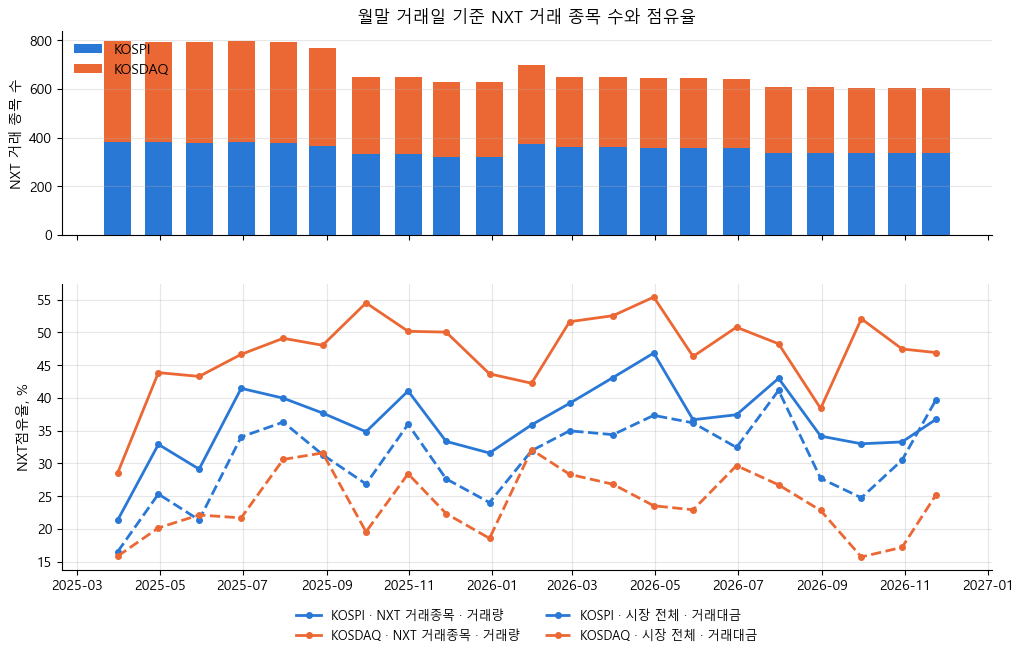

In [11]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True, gridspec_kw={"height_ratios": [1, 1.4]})
x = mpick("NXT 거래종목", "합계", "종목수").index
k_n = mpick("NXT 거래종목", "KOSPI", "종목수").reindex(x).fillna(0)
q_n = mpick("NXT 거래종목", "KOSDAQ", "종목수").reindex(x).fillna(0)
axes[0].bar(x, k_n, width=20, color=MKT_COLOR["KOSPI"], label="KOSPI")
axes[0].bar(x, q_n, width=20, bottom=k_n, color=MKT_COLOR["KOSDAQ"], label="KOSDAQ")
axes[0].set_ylabel("NXT 거래 종목 수"); axes[0].legend(frameon=False, loc="upper left"); axes[0].grid(axis="y", alpha=.3)
axes[0].set_title("월말 거래일 기준 NXT 거래 종목 수와 점유율")
for uni, col, ls, lab in [("NXT 거래종목", "NXT점유율(%)", "-", "NXT 거래종목 · 거래량"),
                          ("시장 전체", "NXT대금점유율(%)", "--", "시장 전체 · 거래대금")]:
    for m in MARKETS:
        s = mpick(uni, m, col)
        axes[1].plot(s.index, s.values, color=MKT_COLOR[m], ls=ls, lw=2, marker="o", ms=4, label=f"{m} · {lab}")
axes[1].set_ylabel("NXT점유율, %"); axes[1].grid(alpha=.3); axes[1].legend(frameon=False, fontsize=9, ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.1))
plt.show()

## 결과 읽는 법과 한계
- **NXT 거래종목 기준**은 "NXT가 거래하는 종목에서 NXT가 얼마나 가져가나", **시장 전체 기준**은 "코스피·코스닥 전체 거래에서 NXT 몫"입니다.
  종목 수가 늘어나는 시기에는 두 번째가 오르는데 첫 번째는 그대로일 수 있습니다.
- 종목별 기간 점유율은 기간 합계로 다시 계산한 값이고, 그 종목이 NXT 목록에 있던 날만 셉니다.
  `NXT거래일수`가 구간 거래일수보다 적은 종목은 구간 중에 NXT에 들어왔거나 빠진 종목입니다.
- 일별·월별 "시장 전체" 점유율은 그날 NXT에 없던 종목의 KRX 거래도 분모에 넣습니다. 이것이 "시장 전체에서 NXT 몫"의 정의입니다.
- NXT 거래량은 애프터마켓(~20:00)까지 포함하고, NXT 거래대금에는 대량·바스켓 대금이 없습니다(1-01 참고).
- 월말 하루 표본은 추세를 보기 위한 것입니다. 정확한 월평균이 필요하면 그달의 모든 거래일을 받아 합산하세요.